# Practice 2: Hands-on Practice with Pre-trained Neural Network Architectures
## Chương 3.2: So sánh & Trực quan hóa các Kiến trúc Pre-trained (ResNet-18 vs VGG16 vs DenseNet121)

- **Học phần:** Deep Learning - UTH
- **Sinh viên phụ trách:** Lưu Nhựt Tân
- **Mục tiêu thực nghiệm:**
  1. Trực quan hóa phân tích cấu trúc tham số (Total vs Trainable Parameters) sau khi đóng băng backbone.
  2. So sánh Trade-off giữa độ phức tạp tính toán (FLOPs) và độ chính xác phân loại Top-1 trên ImageNet.
  3. Trực quan hóa dữ liệu CIFAR-10 và thực thi suy luận (Forward Pass) kiểm tra đầu ra trên cả 3 kiến trúc.

In [1]:
import sys
import os
sys.path.append(os.path.abspath('..'))

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np

from src.model_builder import (
    TransferModelBuilder,
    TransferModelBuilder_ResNet18,
    TransferModelBuilder_VGG16,
    TransferModelBuilder_DenseNet121,
)
from src.data_module import CIFAR10DataModule

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Thiết bị thực thi (Device): {device}')

Thiết bị thực thi (Device): cpu


In [2]:
# Khởi tạo 3 mô hình Transfer Learning cho bài toán CIFAR-10 (10 lớp)
resnet_builder = TransferModelBuilder(model_name='resnet18', num_classes=10, pretrained=True)
vgg_builder = TransferModelBuilder(model_name='vgg16', num_classes=10, pretrained=True)
densenet_builder = TransferModelBuilder(model_name='densenet121', num_classes=10, pretrained=True)

model_resnet = resnet_builder.build().to(device)
model_vgg = vgg_builder.build().to(device)
model_densenet = densenet_builder.build().to(device)

print('✓ Đã khởi tạo thành công ResNet-18, VGG16 và DenseNet121 với backbone đã đóng băng!')

✓ Đã khởi tạo thành công ResNet-18, VGG16 và DenseNet121 với backbone đã đóng băng!


In [3]:
def get_model_stats(name, model):
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    frozen_params = total_params - trainable_params
    trainable_ratio = (trainable_params / total_params) * 100
    return {
        'name': name,
        'total': total_params,
        'frozen': frozen_params,
        'trainable': trainable_params,
        'ratio': trainable_ratio
    }

stats = [
    get_model_stats('ResNet-18', model_resnet),
    get_model_stats('VGG16', model_vgg),
    get_model_stats('DenseNet121', model_densenet),
]

print(f"{'Mô hình':<15} | {'Tổng tham số':<15} | {'Backbone đóng băng':<18} | {'Head huấn luyện':<15} | {'Tỷ lệ cập nhật (%)':<15}")
print('-' * 88)
for s in stats:
    print(f"{s['name']:<15} | {s['total']:>14,} | {s['frozen']:>18,} | {s['trainable']:>18,} | {s['ratio']:>17.3f}%")

Mô hình         | Tổng tham số    | Backbone đóng băng | Head huấn luyện | Tỷ lệ cập nhật (%)
----------------------------------------------------------------------------------------
ResNet-18       |     11,181,642 |         11,176,512 |              5,130 |             0.046%
VGG16           |    134,301,514 |        134,260,544 |             40,970 |             0.031%
DenseNet121     |      6,964,106 |          6,953,856 |             10,250 |             0.147%


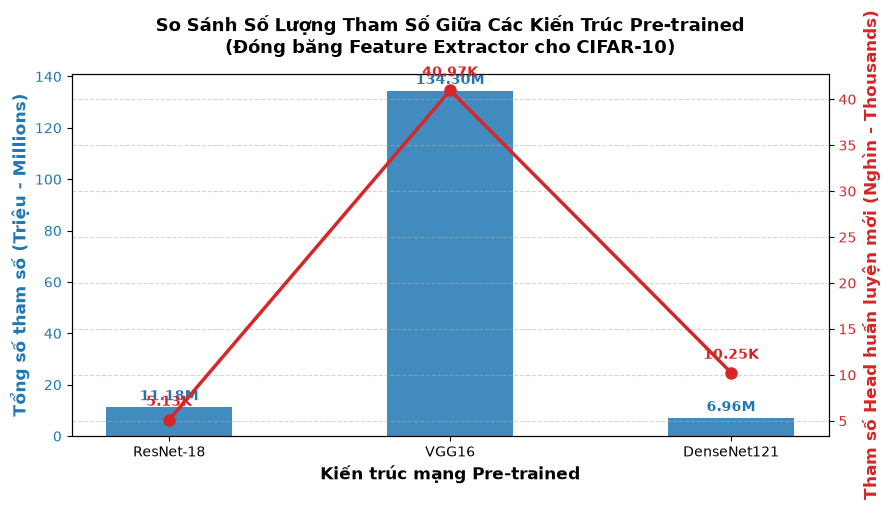

In [4]:
models_name = [s['name'] for s in stats]
total_m = [s['total'] / 1e6 for s in stats]
trainable_k = [s['trainable'] / 1e3 for s in stats]

fig, ax1 = plt.subplots(figsize=(9, 5))

color = '#1f77b4'
ax1.set_xlabel('Kiến trúc mạng Pre-trained', fontsize=12, fontweight='bold')
ax1.set_ylabel('Tổng số tham số (Triệu - Millions)', color=color, fontsize=12, fontweight='bold')
bars1 = ax1.bar(models_name, total_m, color=color, width=0.45, alpha=0.85, label='Tổng tham số (M)')
ax1.tick_params(axis='y', labelcolor=color)

for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f'{yval:.2f}M', ha='center', va='bottom', fontweight='bold', color=color)

ax2 = ax1.twinx()
color2 = '#d62728'
ax2.set_ylabel('Tham số Head huấn luyện mới (Nghìn - Thousands)', color=color2, fontsize=12, fontweight='bold')
ax2.plot(models_name, trainable_k, color=color2, marker='o', linewidth=2.5, markersize=8, label='Trainable Head (K)')
ax2.tick_params(axis='y', labelcolor=color2)

for i, txt in enumerate(trainable_k):
    ax2.annotate(f'{txt:.2f}K', (models_name[i], txt), textcoords='offset points', xytext=(0,10), ha='center', fontweight='bold', color=color2)

plt.title('So Sánh Số Lượng Tham Số Giữa Các Kiến Trúc Pre-trained\n(Đóng băng Feature Extractor cho CIFAR-10)', fontsize=13, fontweight='bold', pad=15)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

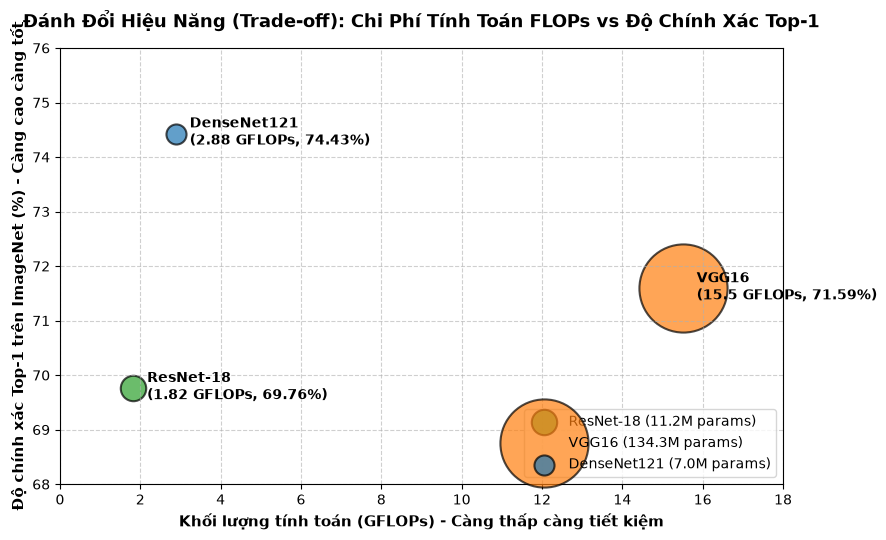

In [5]:
gflops = [1.82, 15.50, 2.88]
top1_acc = [69.76, 71.59, 74.43]
params_size = [s['total'] / 1e6 * 20 for s in stats]

plt.figure(figsize=(9, 5.5))
colors = ['#2ca02c', '#ff7f0e', '#1f77b4']

for i, name in enumerate(models_name):
    plt.scatter(gflops[i], top1_acc[i], s=params_size[i] * 1.5, color=colors[i], alpha=0.7, edgecolors='black', linewidth=1.5, label=f'{name} ({total_m[i]:.1f}M params)')
    plt.text(gflops[i] + 0.35, top1_acc[i] - 0.2, f'{name}\n({gflops[i]} GFLOPs, {top1_acc[i]}%)', fontsize=10, fontweight='bold')

plt.title('Đánh Đổi Hiệu Năng (Trade-off): Chi Phí Tính Toán FLOPs vs Độ Chính Xác Top-1', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Khối lượng tính toán (GFLOPs) - Càng thấp càng tiết kiệm', fontsize=11, fontweight='bold')
plt.ylabel('Độ chính xác Top-1 trên ImageNet (%) - Càng cao càng tốt', fontsize=11, fontweight='bold')
plt.xlim(0, 18)
plt.ylim(68, 76)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

In [6]:
data_module = CIFAR10DataModule(
    data_dir='../data',
    batch_size=8,
    image_size=224,
    num_workers=0,
)
data_module.setup()
test_loader = data_module.test_dataloader()

images, labels = next(iter(test_loader))
print(f'Batch ảnh: {images.shape}, Batch nhãn: {labels.shape}')

cifar10_classes = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

Batch ảnh: torch.Size([8, 3, 224, 224]), Batch nhãn: torch.Size([8])


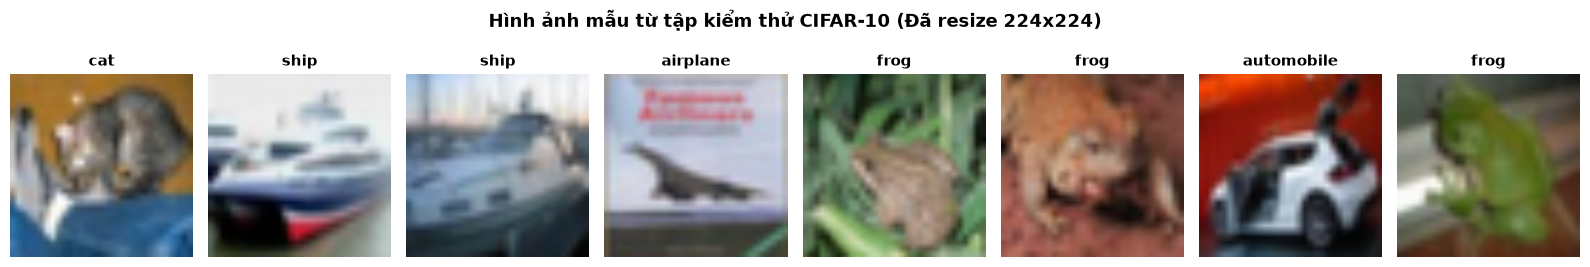

In [7]:
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
for idx in range(8):
    img = images[idx].permute(1, 2, 0).cpu().numpy()
    img = std * img + mean
    img = np.clip(img, 0, 1)
    axes[idx].imshow(img)
    axes[idx].set_title(cifar10_classes[labels[idx].item()], fontsize=11, fontweight='bold')
    axes[idx].axis('off')

plt.suptitle('Hình ảnh mẫu từ tập kiểm thử CIFAR-10 (Đã resize 224x224)', fontsize=13, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

ResNet-18 Output Shape   : torch.Size([8, 10])
VGG-16 Output Shape      : torch.Size([8, 10])
DenseNet-121 Output Shape: torch.Size([8, 10])


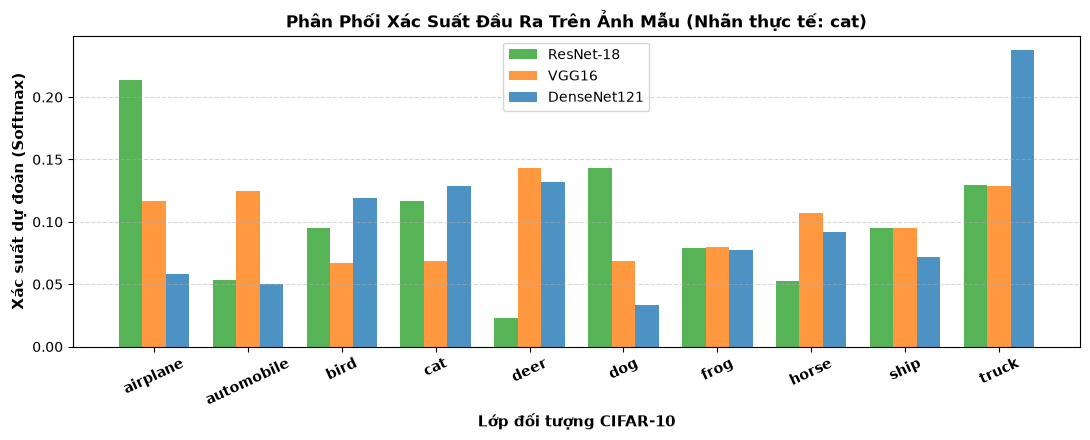

In [8]:
images_device = images.to(device)

model_resnet.eval()
model_vgg.eval()
model_densenet.eval()

with torch.no_grad():
    out_res = model_resnet(images_device)
    out_vgg = model_vgg(images_device)
    out_dense = model_densenet(images_device)

print(f'ResNet-18 Output Shape   : {out_res.shape}')
print(f'VGG-16 Output Shape      : {out_vgg.shape}')
print(f'DenseNet-121 Output Shape: {out_dense.shape}')

probs_res = torch.softmax(out_res[0], dim=0).cpu().numpy()
probs_vgg = torch.softmax(out_vgg[0], dim=0).cpu().numpy()
probs_dense = torch.softmax(out_dense[0], dim=0).cpu().numpy()

x = np.arange(len(cifar10_classes))
width = 0.25

plt.figure(figsize=(11, 4.5))
plt.bar(x - width, probs_res, width, label='ResNet-18', color='#2ca02c', alpha=0.8)
plt.bar(x, probs_vgg, width, label='VGG16', color='#ff7f0e', alpha=0.8)
plt.bar(x + width, probs_dense, width, label='DenseNet121', color='#1f77b4', alpha=0.8)

plt.xlabel('Lớp đối tượng CIFAR-10', fontsize=11, fontweight='bold')
plt.ylabel('Xác suất dự đoán (Softmax)', fontsize=11, fontweight='bold')
plt.title(f'Phân Phối Xác Suất Đầu Ra Trên Ảnh Mẫu (Nhãn thực tế: {cifar10_classes[labels[0].item()]})', fontsize=12, fontweight='bold')
plt.xticks(x, cifar10_classes, rotation=25, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()